In [2]:
import numpy as ap
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

In [16]:
df = pd.read_csv("C:/Users/Mohd Ishan/Desktop/CustSight/data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
pd.set_option('display.max_columns',None)

#EDA

In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [18]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Unnamed: 21
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,NaN
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No,NaN
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,NaN
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,NaN
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,NaN


In [19]:
df = df.drop(columns='Unnamed: 21')

In [20]:
df = df.drop_duplicates()

In [42]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

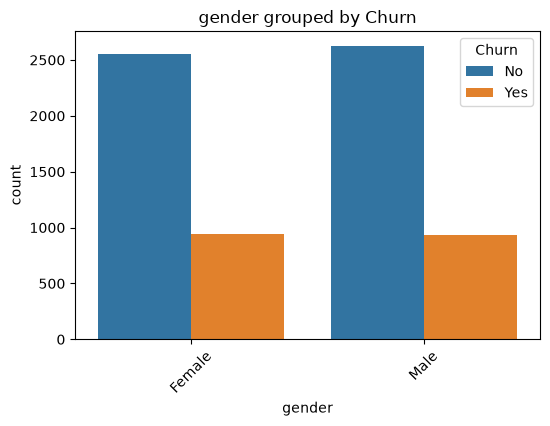

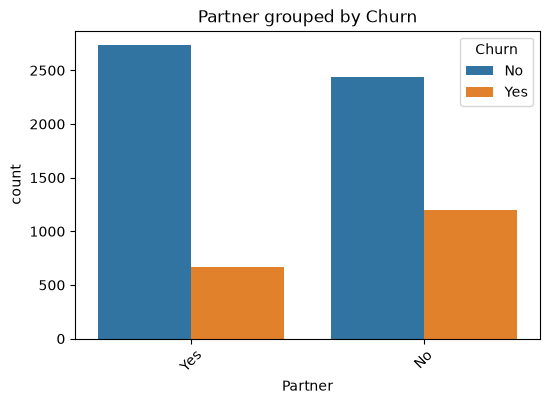

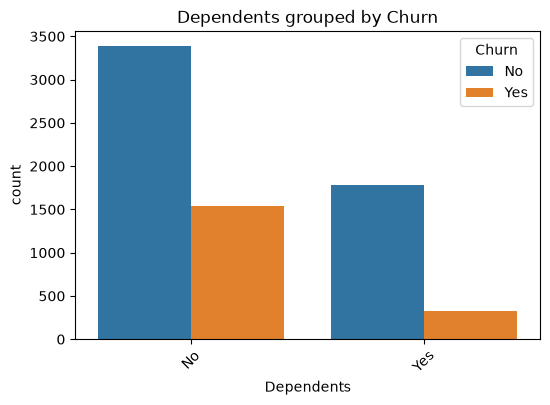

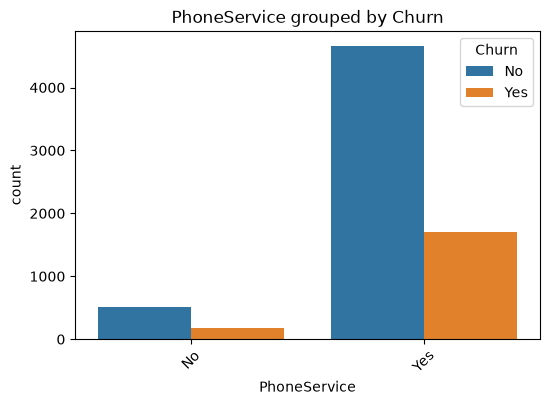

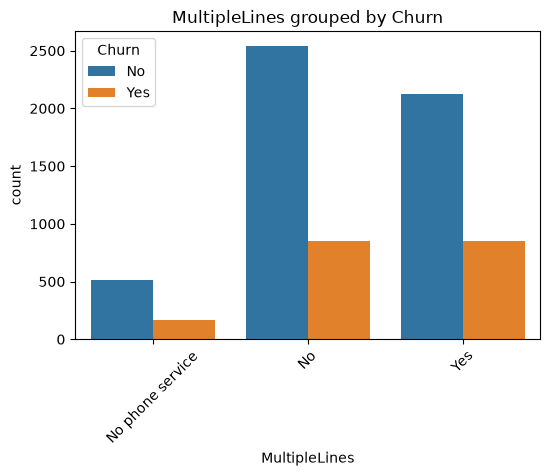

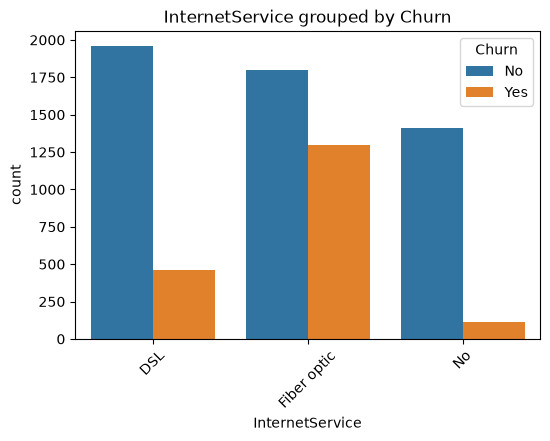

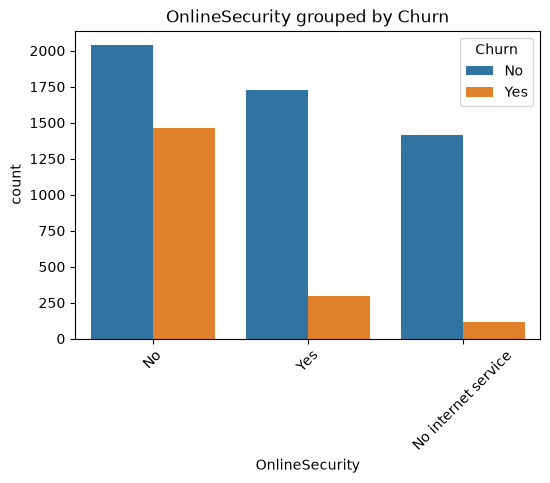

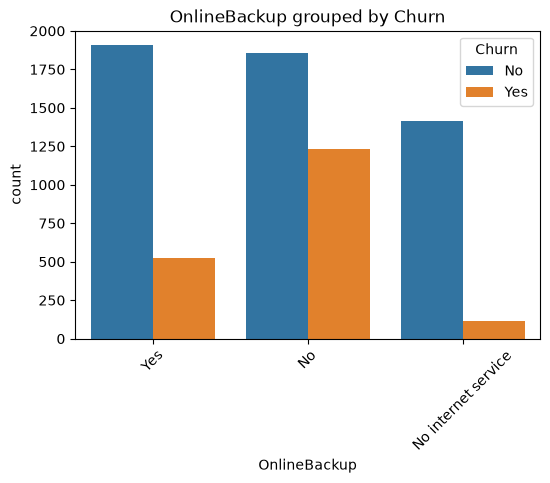

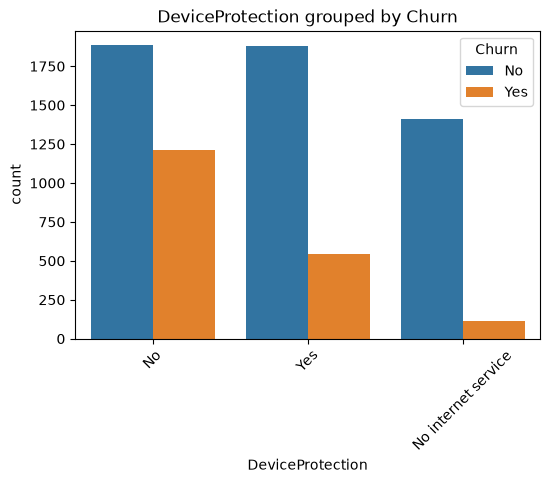

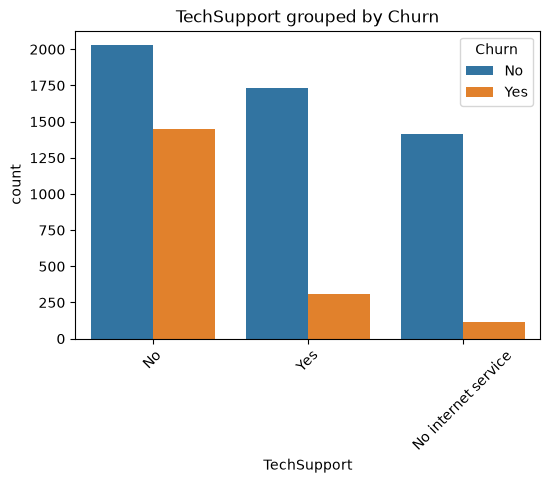

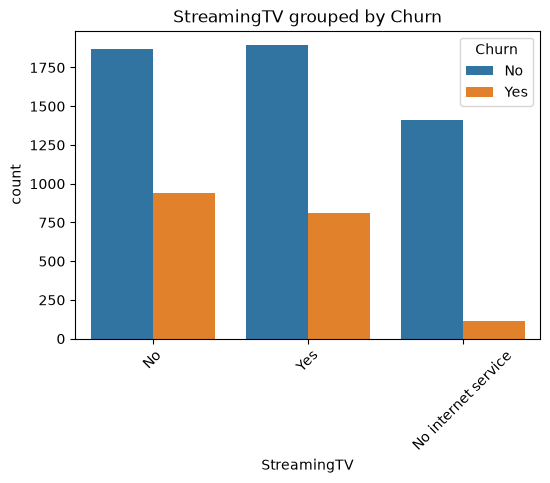

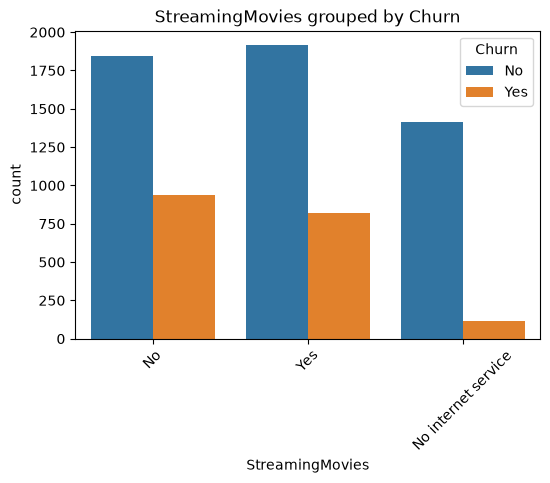

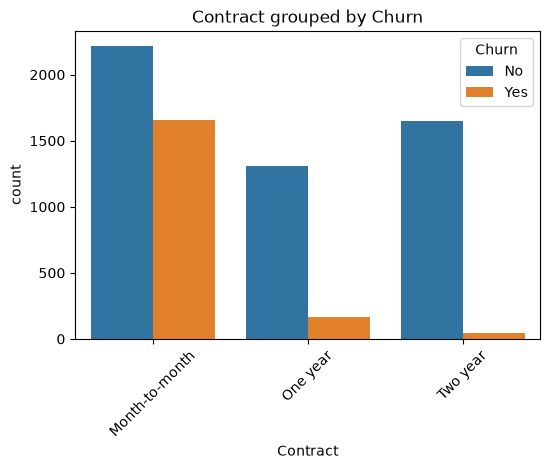

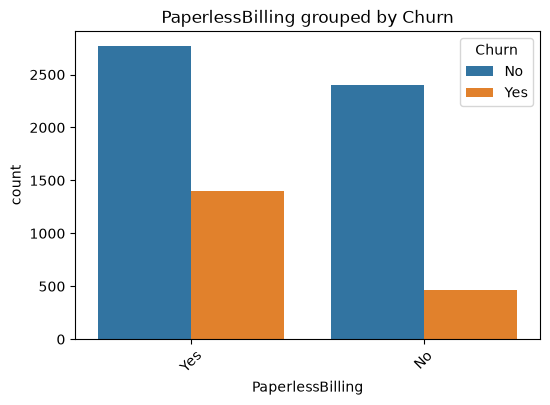

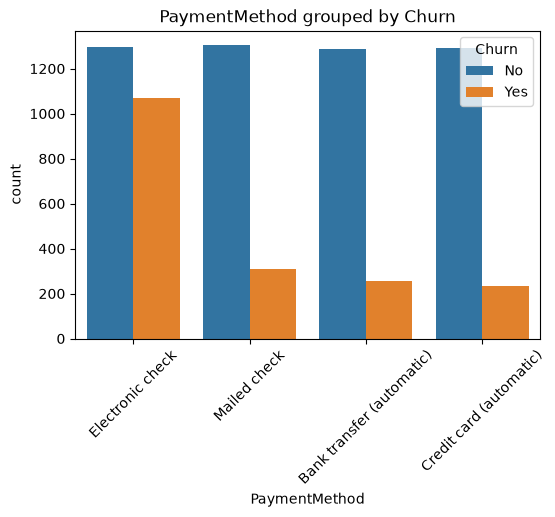

In [15]:
df_plot = df.drop(columns=["customerID", "tenure", "TotalCharges","MonthlyCharges","SeniorCitizen"])

for col in df_plot.columns:
    if col == "Churn" :
        continue
    plt.figure(figsize=(6, 4))
    if df_plot[col].dtype in ['int64', 'float64']:
        sb.scatterplot(data=df_plot, x=col, y="Churn")
        plt.title(f"{col} vs {"Churn"} (Scatter Plot)")
    else:
        sb.countplot(data=df_plot, x=col, hue="Churn")
        plt.title(f"{col} grouped by {"Churn"}")
        plt.xticks(rotation=45)

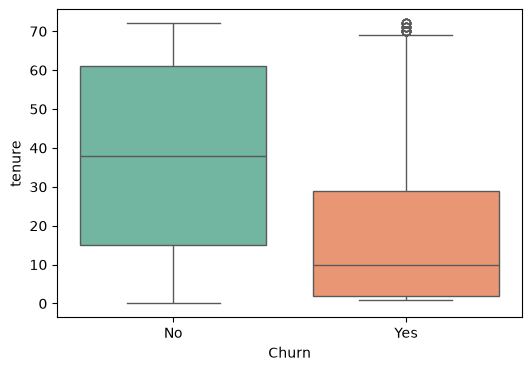

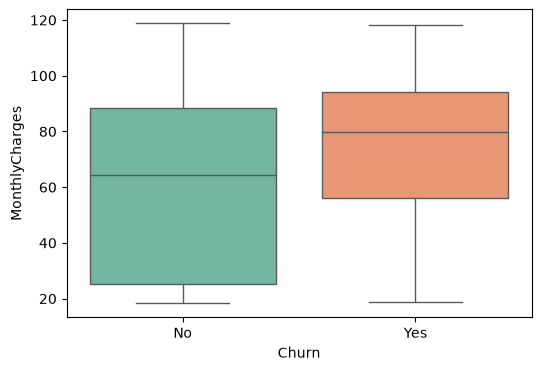

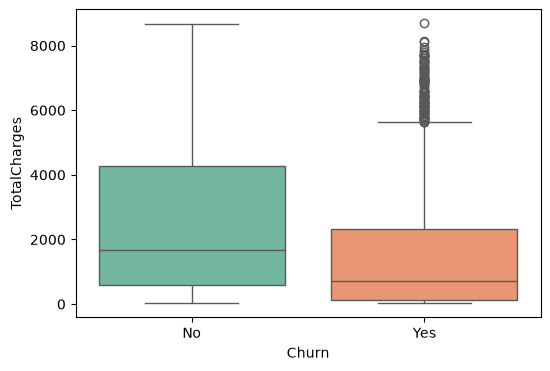

In [43]:
columns_to_plot = ["tenure", "MonthlyCharges", "TotalCharges"]

for col in columns_to_plot:
    plt.figure(figsize=(6, 4))
    sb.boxplot( data=df, x="Churn", y=col, hue="Churn", palette="Set2", legend=False)

<Axes: >

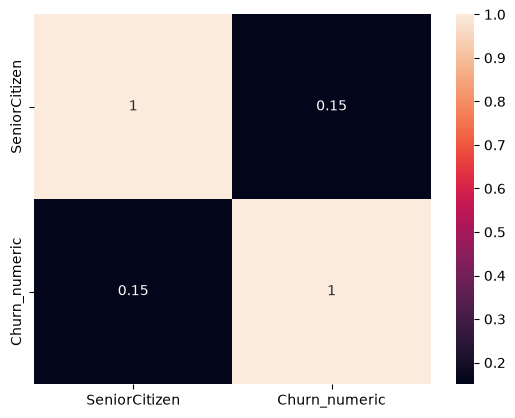

In [36]:
df['Churn_numeric'] = df['Churn'].map({'Yes': 1, 'No': 0})
corr_matrix = df[["SeniorCitizen", "Churn_numeric"]].corr()
sb.heatmap(corr_matrix, annot=True)